# 03 — Run Retrieval Experiments

This notebook runs all three retrieval strategies against the 40-question benchmark and saves the results.

**Strategies tested:**
- `vanilla`: Pure cosine similarity, no filters
- `metadata_filtered`: Pre-filter by ticker + year, then similarity search
- `task_aware`: Routes to split-budget retrieval for cross-year/cross-company tasks

**Output:** `data/processed/retrieval_results.parquet` — long-format table with one row per (question, strategy, retrieved_chunk).

**Runtime:** ~3–5 minutes (120 queries × 3 strategies = 360 embedding calls).

In [1]:
import sys
sys.path.insert(0, '..')

import os
import pandas as pd

from src.config import PROCESSED_DIR, TOP_K
from src.retrieval import (
    get_qdrant_client,
    vanilla_retrieval,
    metadata_filtered_retrieval,
    task_aware_retrieval,
    run_retrieval_experiments,
)

questions_path = os.path.join(PROCESSED_DIR, 'questions.csv')
questions_df = pd.read_csv(questions_path)
print(f"Loaded {len(questions_df)} questions")
print(questions_df['task_type'].value_counts())

Loaded 40 questions
task_type
single_fact      10
risk_factor      10
cross_year       10
cross_company    10
Name: count, dtype: int64


## 3.1 — Connect to Qdrant and verify collection

In [2]:
from src.config import QDRANT_COLLECTION

client = get_qdrant_client()
info = client.get_collection(QDRANT_COLLECTION)
print(f"Collection: {QDRANT_COLLECTION}")
print(f"  Points: {info.points_count}")
print(f"  Vectors: {info.points_count}")

if info.points_count == 0:
    raise RuntimeError("Collection is empty! Run notebook 02 first to upsert chunks.")

Collection: sec_filings
  Points: 2916
  Vectors: 2916


## 3.2 — Single question demo

Compare how the three strategies retrieve different context for the same question.

In [3]:
demo_q = questions_df[questions_df['task_type'] == 'cross_year'].iloc[0]
question = demo_q['question']
ticker = demo_q['ticker']
year = int(demo_q['year'])
comp_year = int(demo_q['comparison_year']) if pd.notna(demo_q['comparison_year']) else None

print(f"Question: {question}")
print(f"Expected: {ticker} | years: {year} vs {comp_year}")
print("\n" + "="*80)

vanilla_results = vanilla_retrieval(client, question, top_k=TOP_K)
filtered_results = metadata_filtered_retrieval(client, question, ticker=ticker, year=year, top_k=TOP_K)
task_results = task_aware_retrieval(
    client, question,
    task_type='cross_year',
    companies=[ticker],
    years=[year, comp_year],
    top_k=TOP_K
)

for strategy, results in [('vanilla', vanilla_results), ('metadata_filtered', filtered_results), ('task_aware', task_results)]:
    print(f"\n--- {strategy.upper()} ---")
    tickers_retrieved = [r['ticker'] for r in results]
    years_retrieved = [r['year'] for r in results]
    print(f"  Tickers: {tickers_retrieved}")
    print(f"  Years:   {years_retrieved}")
    for r in results:
        print(f"  [{r['ticker']} {r['year']} {r['section']}] score={r['score']:.3f}")

Question: How did NVIDIA's description of AI and data center demand evolve between its 2022 and 2024 10-K filings?
Expected: NVDA | years: 2022 vs 2024




--- VANILLA ---
  Tickers: ['NVDA', 'NVDA', 'NVDA', 'NVDA', 'NVDA']
  Years:   [2024, 2023, 2024, 2022, 2024]
  [NVDA 2024 MD&A] score=0.693
  [NVDA 2023 MD&A] score=0.684
  [NVDA 2024 Business] score=0.672
  [NVDA 2022 MD&A] score=0.666
  [NVDA 2024 MD&A] score=0.666

--- METADATA_FILTERED ---
  Tickers: ['NVDA', 'NVDA', 'NVDA', 'NVDA', 'NVDA']
  Years:   [2022, 2022, 2022, 2022, 2022]
  [NVDA 2022 MD&A] score=0.666
  [NVDA 2022 MD&A] score=0.645
  [NVDA 2022 Business] score=0.644
  [NVDA 2022 Business] score=0.638
  [NVDA 2022 Other] score=0.630

--- TASK_AWARE ---
  Tickers: ['NVDA', 'NVDA', 'NVDA', 'NVDA']
  Years:   [2022, 2022, 2024, 2024]
  [NVDA 2022 MD&A] score=0.666
  [NVDA 2022 MD&A] score=0.645
  [NVDA 2024 MD&A] score=0.693
  [NVDA 2024 Business] score=0.672


## 3.3 — Run full retrieval experiment

This runs all 40 questions × 3 strategies = 120 retrieval calls.

In [4]:
output_path = os.path.join(PROCESSED_DIR, 'retrieval_results.parquet')

if os.path.exists(output_path):
    print(f"Loading existing results from {output_path}")
    retrieval_df = pd.read_parquet(output_path)
else:
    print("Running retrieval experiments...")
    retrieval_df = run_retrieval_experiments(questions_df, client=client)
    retrieval_df.to_parquet(output_path, index=False)
    print(f"Saved to {output_path}")

print(f"\nShape: {retrieval_df.shape}")
print(f"Strategies: {retrieval_df['strategy'].unique()}")
retrieval_df.head()

Running retrieval experiments...


Retrieval experiments:   0%|          | 0/40 [00:00<?, ?it/s]

Retrieval experiments:   2%|▎         | 1/40 [00:00<00:35,  1.09it/s]

Retrieval experiments:   5%|▌         | 2/40 [00:01<00:32,  1.16it/s]

Retrieval experiments:   8%|▊         | 3/40 [00:02<00:33,  1.12it/s]

...

Retrieval experiments:  98%|█████████▊| 39/40 [00:38<00:01,  1.14s/it]

Retrieval experiments: 100%|██████████| 40/40 [00:39<00:00,  1.11s/it]

Retrieval experiments: 100%|██████████| 40/40 [00:39<00:00,  1.00it/s]

Saved to /Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/../data/processed/retrieval_results.parquet

Shape: (580, 10)
Strategies: ['vanilla' 'metadata_filtered' 'task_aware']


,question_id,strategy,rank,chunk_id,ticker,company,year,section,text,score
0,Q001,vanilla,0,AAPL_2023_md_a_0000,AAPL,Apple Inc.,2023,MD&A,Item 7. Management’s Discussion and Analysi...,0.690380
1,Q001,vanilla,1,AAPL_2023_financial_statements_0005,AAPL,Apple Inc.,2023,Financial Statements,"charged by the Company for similar offerings,...",0.682636
2,Q001,vanilla,2,AAPL_2023_md_a_0001,AAPL,Apple Inc.,2023,MD&A,and financial condition.\nApple Inc. | 2023 F...,0.671481
3,Q001,vanilla,3,AAPL_2024_financial_statements_0005,AAPL,Apple Inc.,2024,Financial Statements,"obligation including, where applicable, price...",0.661671
4,Q001,vanilla,4,AAPL_2022_financial_statements_0021,AAPL,Apple Inc.,2022,Financial Statements,"wearables and accessories. Therefore, many co...",0.652749


## 3.4 — Retrieval quality analysis

For questions with a specific expected ticker and year, compute how often the correct entity appears in the top-5.

In [5]:
# Merge question metadata into retrieval results
merged = retrieval_df.merge(
    questions_df[['question_id', 'task_type', 'ticker', 'year']].rename(
        columns={'ticker': 'expected_ticker', 'year': 'expected_year'}
    ),
    on='question_id',
    how='left'
)

# Entity hit rate: expected ticker appears in retrieved chunks
def entity_hit(group, expected_ticker_col='expected_ticker'):
    expected = group[expected_ticker_col].iloc[0]
    return expected in group['ticker'].values

hit_rate = (
    merged[merged['expected_ticker'].notna()]
    .groupby(['question_id', 'strategy', 'task_type', 'expected_ticker'])
    .apply(entity_hit)
    .reset_index(name='entity_hit')
)

print("Entity hit rate by strategy:")
print(hit_rate.groupby('strategy')['entity_hit'].mean().round(3))

print("\nEntity hit rate by strategy × task_type:")
print(hit_rate.groupby(['strategy', 'task_type'])['entity_hit'].mean().unstack().round(3))

Entity hit rate by strategy:
strategy
metadata_filtered    1.0
task_aware           1.0
vanilla              0.9
Name: entity_hit, dtype: float64

Entity hit rate by strategy × task_type:
task_type          cross_company  cross_year  risk_factor  single_fact
strategy                                                              
metadata_filtered            1.0         1.0          1.0          1.0
task_aware                   1.0         1.0          1.0          1.0
vanilla                      0.6         1.0          1.0          1.0


/var/folders/1y/42jcd32x74sfkj7xjlx937xm0000gn/T/ipykernel_97519/1507207507.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  merged[merged['expected_ticker'].notna()]


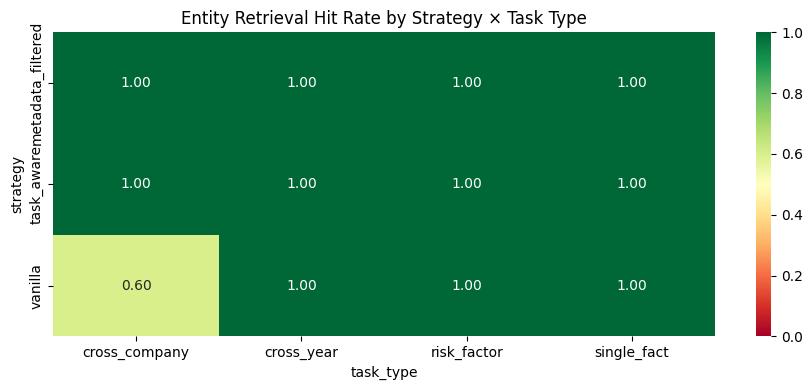

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

hit_pivot = hit_rate.groupby(['strategy', 'task_type'])['entity_hit'].mean().reset_index()
hit_pivot = hit_pivot.pivot(index='strategy', columns='task_type', values='entity_hit')

plt.figure(figsize=(9, 4))
sns.heatmap(hit_pivot, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Entity Retrieval Hit Rate by Strategy × Task Type')
plt.tight_layout()
plt.savefig('../figures/retrieval_hit_rate.png', dpi=150, bbox_inches='tight')
plt.show()